# Prueba Intertrimestral

**Nombre:**  Lucía
**Apellidos:**  Álvarez Castro

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from __future__ import annotations
from pathlib import Path

from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.metrics import (
    mean_squared_error,
    r2_score
    )
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [2]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type == "classic":
        if is_member == False:
            tarifa = 1 + 0.05*duration_min
            return round(tarifa,2)
        else:
            tarifa = (1 + 0.05*duration_min)*0.8
            return round(tarifa,2)

    if bike_type == "electric":
        if is_member == False:
            tarifa = 1.5 + 0.08*duration_min
            return round(tarifa,2)
        else:
            tarifa = (1.5 + 0.08*duration_min)*0.8
            return round(tarifa,2)
    else:
                raise ValueError("Tipo de bicicleta no válido")

In [3]:
rental_fee(26, "classic", False)

2.3

In [4]:
rental_fee(26, "black", False)

ValueError: Tipo de bicicleta no válido

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [5]:
def demand_label(total_rentals, treshold):
    if (total_rentals >= treshold):
        demanda = "Alta"
        return demanda
    elif (treshold/2 <=total_rentals < treshold):
        demanda = "Media"
        return demanda
    else:
        demanda = "Baja"
        return demanda

In [6]:
demand_label(78, 23)

'Alta'

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [7]:
tripsDemo = pd.DataFrame({
    "duration_min": [5.0, 13.0, 15.0, 26.0, 24.0, 38.0, 3.0, 46.0, 15.0, 8.0],
    "bike_type": ["classic", "electric", "classic", "classic", "electric", "classic", "electric", "electric", "classic", "classic"],
    "is_member": [False, True, False, False, True, False, False, True, True, True],
    "total_rentals": [5, 12, 9, 27, 23, 13, 28, 9, 17, 8],
})

tripsDemo["fee"] = [rental_fee(d, b, m) for d, b, m in
                    zip(tripsDemo["duration_min"], tripsDemo["bike_type"], tripsDemo["is_member"])]

tripsDemo["demand"] = tripsDemo["total_rentals"].map(lambda row: demand_label(row, 40))

In [8]:
tripsDemo

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,5.0,classic,False,5,1.25,Baja
1,13.0,electric,True,12,2.03,Baja
2,15.0,classic,False,9,1.75,Baja
3,26.0,classic,False,27,2.30,Media
4,24.0,electric,True,23,2.74,Media
5,38.0,classic,False,13,2.90,Baja
6,3.0,electric,False,28,1.74,Media
7,46.0,electric,True,9,4.14,Baja
8,15.0,classic,True,17,1.40,Baja
9,8.0,classic,True,8,1.12,Baja


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [9]:
class MicromobilityTools:
    rental_fee = staticmethod(rental_fee)
    demand_label = staticmethod(demand_label)

    def __init__(self, duration_min, bike_type, is_member):
        self.trips = pd.DataFrame({"duration_min": duration_min,
                                   "bike_type": bike_type, 
                                   "is_member": is_member})

    def calculate(self, total_rentals=None, treshold = 40):
        treshold=40
        result = self.trips.copy()
        result["fee"] = [self.rental_fee(d, b, m) for d, b, m in
                         zip(result.duration_min, result.bike_type, result.is_member)]
        result["total_rentals"] = list(total_rentals)
        result["demand"] = [self.demand_label(t, treshold) for t in total_rentals]
        return result

tools_ejemplo = MicromobilityTools(tripsDemo["duration_min"], tripsDemo["bike_type"], tripsDemo["is_member"])
display(tools_ejemplo.calculate(tripsDemo["total_rentals"], treshold = 40))

,duration_min,bike_type,is_member,fee,total_rentals,demand
0,5.0,classic,False,1.25,5,Baja
1,13.0,electric,True,2.03,12,Baja
2,15.0,classic,False,1.75,9,Baja
3,26.0,classic,False,2.30,27,Media
4,24.0,electric,True,2.74,23,Media
5,38.0,classic,False,2.90,13,Baja
6,3.0,electric,False,1.74,28,Media
7,46.0,electric,True,4.14,9,Baja
8,15.0,classic,True,1.40,17,Baja
9,8.0,classic,True,1.12,8,Baja


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [10]:
DATA_DIR = Path.cwd() 

mobilityData_csv = DATA_DIR / "city_micromobility_hourly.csv"
mobilityData = pd.read_csv(mobilityData_csv)
mobilityData.head()

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


In [11]:
mobilityData.shape

(17520, 23)

Tiene 17520 filas y 23 columnas.

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [12]:
def describeData(dataFrame):
    nulos = dataFrame.isna().sum()
    porcentaje_nulos = dataFrame.isna().mean() * 100
    return pd.DataFrame({"tipo": dataFrame.dtypes,
                         "nulos": nulos,
                         "porcentaje_nulos": porcentaje_nulos})

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [13]:
describeData(mobilityData)

,tipo,nulos,porcentaje_nulos
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


Las columnas con más valores faltantes son:
- humidity: 224 nulos, 1.28% de nulos
- wind_kmh: 142 nulos, 0.81% de nulos
- avg_trip_min: 255 nulos, 1.45% de nulos
- electric_share: 182 nulos, 1.04% de nulos

Antes de modelar, hay varias opciones:
- Pueden eliminarse las filas que tengan nulos, ya que constituyen un porcentaje muy pequeño de la muestra completa. Podría comprobarse si los valores nulos siguen algún patrón.
- También pueden imputarse los valores. Debido a que todas las variables son numéricas, podría utilizarse la media o la mediana.

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).


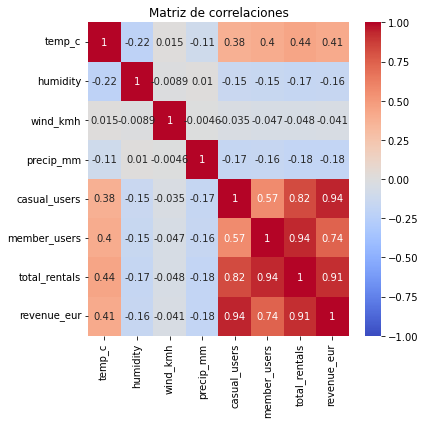

In [14]:
vars_numericas_relevantes = ["temp_c", "humidity", "wind_kmh", "precip_mm", "casual_users", "member_users", "total_rentals", "revenue_eur"]
df_vars_numericas_relevantes = mobilityData[vars_numericas_relevantes]
correlaciones = df_vars_numericas_relevantes.corr()

plt.figure(figsize=(6, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlaciones")
plt.tight_layout()
plt.show()



2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

In [15]:
# demanda media por horas y por fin de semana/laborable
hourly = mobilityData.groupby(["hour", "is_weekend"])["total_rentals"].mean().unstack()

In [16]:
hourly
# el dataframe muestra para cada una de las horas del día (desde las 0 horas hasta las 23 horas) la demanda
# media total según si es fin de semana (fin de semana = 1 y entre semana = 0)

is_weekend,0,1
hour,,
0,9.450192,12.110577
1,9.195402,11.971154
2,9.237548,11.586538
3,9.432950,11.711538
4,9.203065,11.461538
5,9.392720,12.057692
6,37.279693,46.187500
7,68.524904,48.485577
8,68.051724,47.639423


<Figure size 864x432 with 0 Axes>

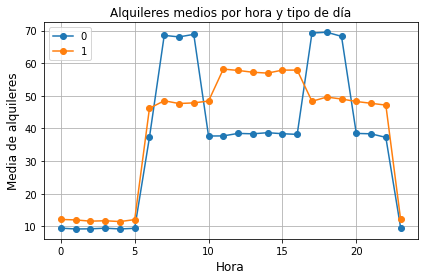

In [17]:
plt.figure(figsize=(12, 6))

hourly.plot(marker="o", title="Alquileres medios por hora y tipo de día")

plt.xlabel("Hora", fontsize = 12)
plt.ylabel("Media de alquileres", fontsize = 12)
plt.legend(loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).

CORRELACIONES:
Algunas variables tienen alta correlación:
- revenue_eur y casual_users: 0.94
- total_rentals y member_users: 0.94
- revenue_eur y total_rentals: 0.91

Estas variables están relacionadas entre sí por motivos evidentes, ya que por ejemplo: la revenue y el número total de alquileres estarán relacionados.

Otras variables relacionadas son temp_c, con una correlación de aproximadamente 0.4 con estas variables que indican el número de alquileres o la revenue. Esto quiere decir que, manteniendo el resto de las variables igual, un aumento de la temperatura aumenta también variables como total_rentals o revenue_eur.
Humedad y precipitaciones se encuentran correlacionadas negativamente: tiene sentido que, manteniendo el resto de variables constantes, un incremento de la humedad y las precipitaciones causen una disminución en el número de alquileres.

HORAS PUNTA:
Entre semana: son las 7, 8 y 9 de la mañana, junto a las 17, 18 y 19. Esto podría ser un indicativo de que los usuarios alquilan estas bicicletas y patinetes para ir/volver del trabajo/colegio/universidad.

Fines de semana: son desde las 11 hasta las 16 horas. Esto puede significar que los usuarios de fin de semana utilizan las bicicletas y patinetes por motivos de ocio. De madrugada también hay un pequeño aumento en la media de alquileres durante los fines de semana, algo que puede estar también relacionado con el ocio nocturno.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [31]:
targetVar = "total_rentals"
predictors = ["hour", "temp_c", "humidity", "precip_mm","wind_kmh", "is_weekend"]
mobilityData_clean = mobilityData.dropna()

X = mobilityData_clean[predictors]
y = mobilityData_clean[targetVar]

In [32]:
X

,hour,temp_c,humidity,precip_mm,wind_kmh,is_weekend
0,0,6.39,67.1,0.0,9.7,0
1,1,4.88,37.2,0.0,2.8,0
2,2,1.72,79.7,0.0,9.0,0
3,3,-3.40,51.4,0.0,5.4,0
4,4,8.24,82.2,0.0,2.4,0
...,...,...,...,...,...,...
17515,19,4.76,67.8,0.0,1.9,0
17516,20,9.53,55.7,0.0,15.8,0
17517,21,10.43,70.4,0.0,4.1,0
17518,22,9.05,56.5,0.0,1.4,0


In [33]:
y

0        10
1         6
2         5
3        12
4         5
         ..
17515    55
17516    22
17517    24
17518    38
17519     7
Name: total_rentals, Length: 16738, dtype: int64

b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [35]:
X_train

,hour,temp_c,humidity,precip_mm,wind_kmh,is_weekend
6258,18,16.77,62.3,0.0,0.9,0
4597,13,35.82,83.0,0.0,14.3,0
1350,6,0.97,34.8,0.0,4.8,0
4299,3,21.61,87.6,0.0,2.0,1
10673,17,27.08,50.4,0.0,1.9,1
...,...,...,...,...,...,...
11806,22,18.24,60.5,0.0,7.2,0
12518,14,33.17,25.2,0.7,1.7,1
5660,20,24.64,67.0,0.0,12.0,1
922,10,17.46,79.9,0.0,6.0,1


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [36]:
lm = LinearRegression()

lm.fit(X_train, y_train)

y_pred = lm.predict(X_test)

r2 = r2_score(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

print(r2)
print(mse)

0.29381408586451063
416.25784364848516


El resultado no es bueno: una R² de 0.29 y un MSE de 418.
Esto quiere decir que el modelo explica el 29% de la variable de alquileres totales. 
Y el error medio sería de 20.45 (raíz cuadrada de 418).

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [37]:
rf = RandomForestRegressor(n_estimators=200, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

y_pred_rf = rf.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)

print("R² Random Forest:", r2_rf)
print("MSE Random Forest:", mse_rf)

R² Random Forest: 0.891439686837001
MSE Random Forest: 63.990347242134604


Random Forest consigue menor MSE y  mayor R². 
Esto se debe a que RF puede representar relaciones no lineales entre las variables.

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [38]:
class_balance = mobilityData["high_demand"].value_counts(dropna=False).sort_index()

In [39]:
class_balance

0    12071
1     5449
Name: high_demand, dtype: int64

b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [40]:
targetVar_class = "high_demand"
predictors_class = ["hour", "temp_c", "humidity", "precip_mm", "wind_kmh", "is_weekend"]

X_class = mobilityData_clean[predictors_class]
y_class = mobilityData_clean[targetVar_class]

In [41]:
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, test_size=0.3, random_state=42, stratify=y_class
)

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_class)
X_test_scaled = scaler.transform(X_test_class)

In [43]:
logistic_model = LogisticRegression(random_state=42, solver='liblinear')
logistic_model.fit(X_train_scaled, y_train_class)

y_pred_class = logistic_model.predict(X_test_scaled)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


In [45]:
# ACCURACY
accuracy_class = accuracy_score(y_test_class, y_pred_class)

print (accuracy_class)

0.748705694942254



Matriz de Confusión (Numérica):
[[3130  329]
 [ 933  630]]


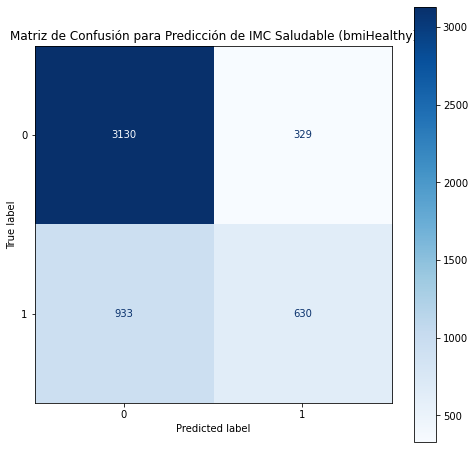

In [46]:
# MATRIZ CONFUSION
cm_class = confusion_matrix(y_test_class, y_pred_class)

print("\nMatriz de Confusión (Numérica):")
print(cm_class)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_class, display_labels=[0, 1]) # 0: No Saludable, 1: Saludable

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Matriz de Confusión para Predicción de IMC Saludable (bmiHealthy)')
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


Importancia de las Variables (Coeficientes de Regresión Logística Estandarizados):
      Feature  Coefficient  Abs_Coefficient
3   precip_mm    -0.871441         0.871441
1      temp_c     0.763938         0.763938
0        hour     0.369919         0.369919
5  is_weekend     0.259317         0.259317
2    humidity    -0.244438         0.244438
4    wind_kmh    -0.159157         0.159157


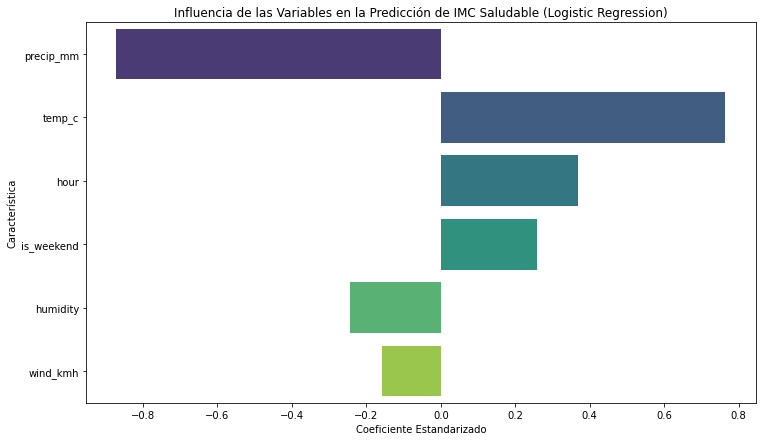

In [47]:
# IMPORTANCIA
coefficients = logistic_model.coef_[0]

predictor_vars_class = X_class.columns

feature_importance = pd.DataFrame({
    'Feature': predictor_vars_class,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False)

print("Importancia de las Variables (Coeficientes de Regresión Logística Estandarizados):")
print(feature_importance)

plt.figure(figsize=(12, 7))
sns.barplot(x='Coefficient', y='Feature', data=feature_importance, palette='viridis')
plt.title('Influencia de las Variables en la Predicción de IMC Saludable (Logistic Regression)')
plt.xlabel('Coeficiente Estandarizado')
plt.ylabel('Característica')
plt.show()

Los factores que más pueden asociarse a la alta demanda son precip_mm, con un coeficiente de -0.87, y temp_c, con un coeficiente de 0.7639.
Como se ha comentado en apartados anteriores, tiene lógica que las lluvias tengan un efecto inverso sobre la alta demanda, ya que, las condiciones climáticas adversas pueden hacer que los usuarios elijan otros medios de transporte que no sean bicicletas o patinetes. 

Como vimos en el gráfico de los alquileres medios por hora según si era fin de semana o entre semana, también tiene lógica que las variables hour o is_weekend tenga una importancia de 0.37 y 0.26 respectivamente.

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



- La demanda cambia a lo largo del día y con el tipo de día:
        - Entre semana: 18:00 (70 alquileres), Fin de semana: 18:00 (50 alquileres). 
        - Entre semana: 12:00 (aprox. 60 alquileres), Fin de semana: 12:00 (aprox. 40 alquileres). 
        
- La temperatura tiene una correlación de 0.44 con el número de alquileres y la precipitación -0.18. 

- En regresión, el mejor modelo es Random Forest: el bosque alcanza R²=0.89 y MSE=64, frente a un R²=0.29 y un MSE=416 de la regresión lineal. 

- La regresión logística alcanza accuracy=0.74.

- Con más tiempo imputaría los valores nulos, ajustaría hiperparámetros con XGBoost y Croos Validation. Tendría también en cuenta las holidays. Revisaría otras métricas aparte de la accuracy, como f1 o precisión.